# 01 — Measuring the Volatility Risk Premium

**Definition.** $VRP(t,\tau) = IV(t,\tau) - RV(t, t+\tau)$ — implied vol observed
at $t$ minus the vol *subsequently realized* over $[t, t+\tau]$.

Two variants live in `vrp_lab.volatility.vrp` and the distinction is the whole game:

| variant | RV leg | usable as a signal? |
|---|---|---|
| `vrp_ex_post` | future window $(t, t+\tau]$ | **No** — look-ahead by construction. Measurement only. |
| `vrp_trailing` | trailing window $(t-\tau, t]$ | Yes — everything observable at $t$. |

This notebook *measures* (ex-post variant). The trading notebooks only ever
consume the trailing variant.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import logging
logging.disable(logging.WARNING)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vrp_lab.config import load_config, PROCESSED, REPORTS
cfg = load_config()
%config InlineBackend.figure_format = "retina"


In [2]:
from vrp_lab.analysis.vrp_study import build_dataset, unconditional_stats, conditional_table
df = build_dataset(save=True)   # cached pulls; offline after first run
df[["close", "vix", "vrp_expost_21d", "vrp_trailing_21d"]].tail()

,close,vix,vrp_expost_21d,vrp_trailing_21d
date,,,,
2026-07-07,747.710022,16.13,NaN,-0.014560
2026-07-08,745.400024,16.90,NaN,0.017882
2026-07-09,751.710022,15.84,NaN,0.004686
2026-07-10,754.950012,15.03,NaN,-0.003799
2026-07-13,749.169983,15.03,NaN,0.003928


## The premium through time
Red bands are VIX > 25 episodes — the moments the insurance seller pays out.

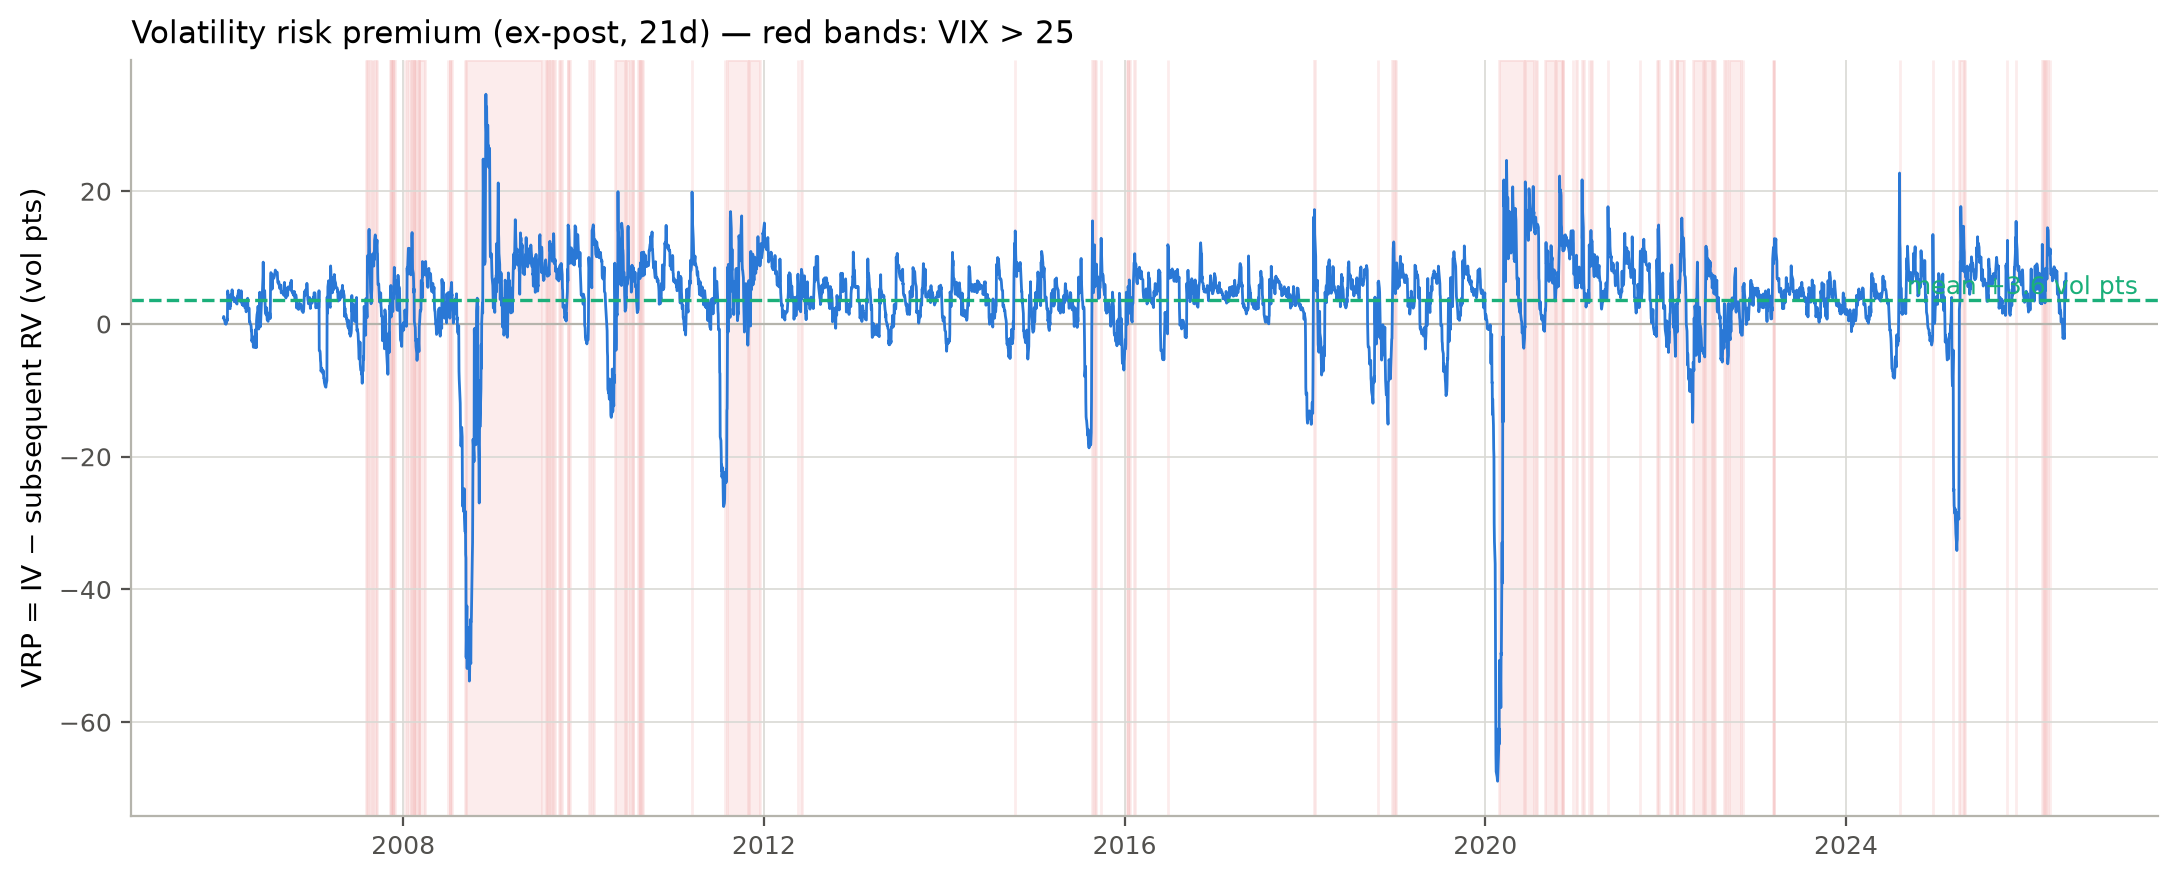

In [3]:
from vrp_lab.visualization.plots import (plot_vrp_timeseries, plot_vrp_histogram,
                                          plot_vrp_vs_vix)
plot_vrp_timeseries(df["vrp_expost_21d"], df["vix"]);

In [4]:
unconditional_stats(df["vrp_expost_21d"]).round(2)

mean_vol_pts         3.59
median_vol_pts       4.52
share_positive       0.84
p5                  -7.05
p95                 11.92
min                -68.89
skew                -3.56
n_days            5141.00
Name: vrp_expost_21d, dtype: float64

The headline: **mean ≈ +3.6 vol points, positive on ~84% of days** — and a minimum of −69 points (Feb-2020 entry dates whose forward window caught the COVID crash). Selling vol collects a steady coupon and occasionally hands back years of it in a month.

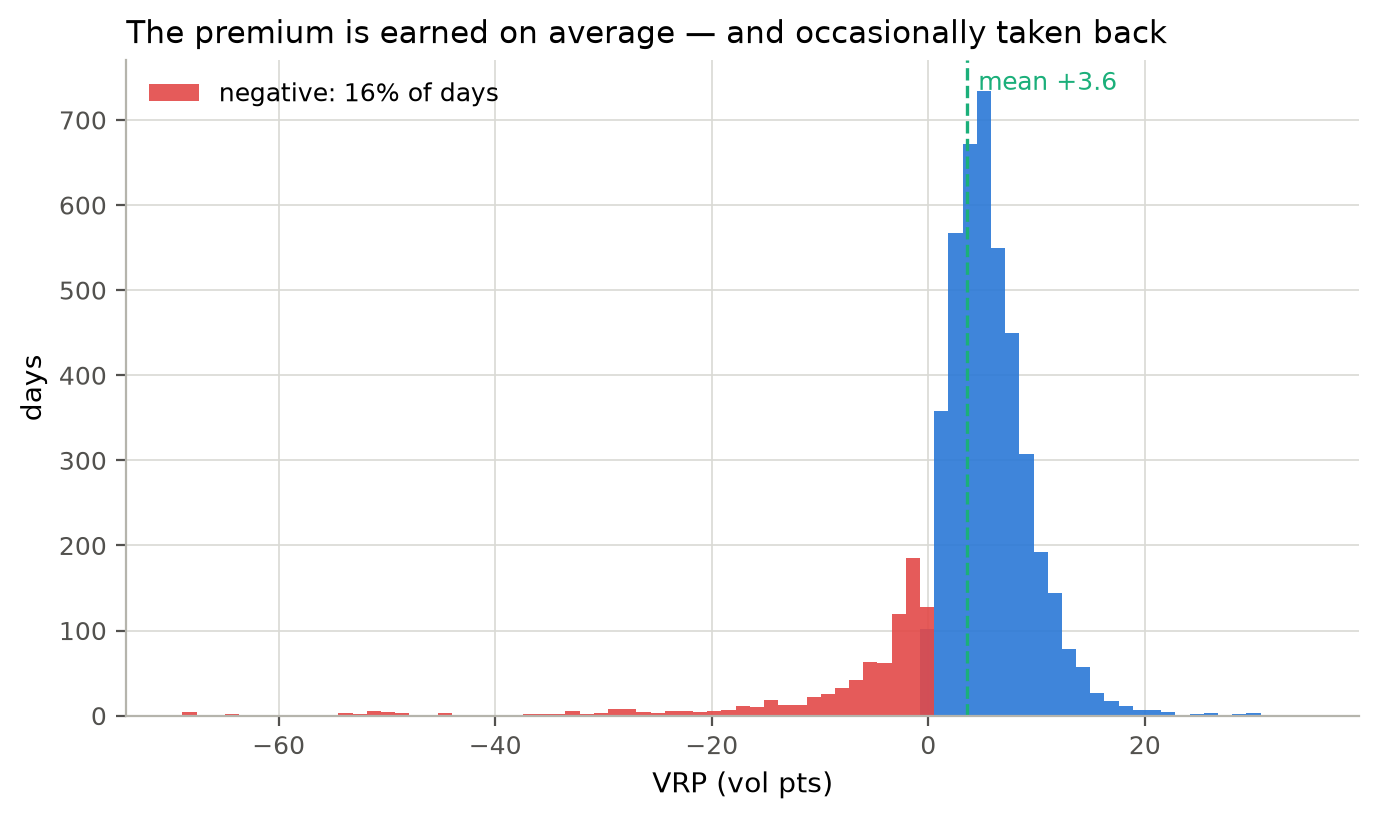

In [5]:
plot_vrp_histogram(df["vrp_expost_21d"]);

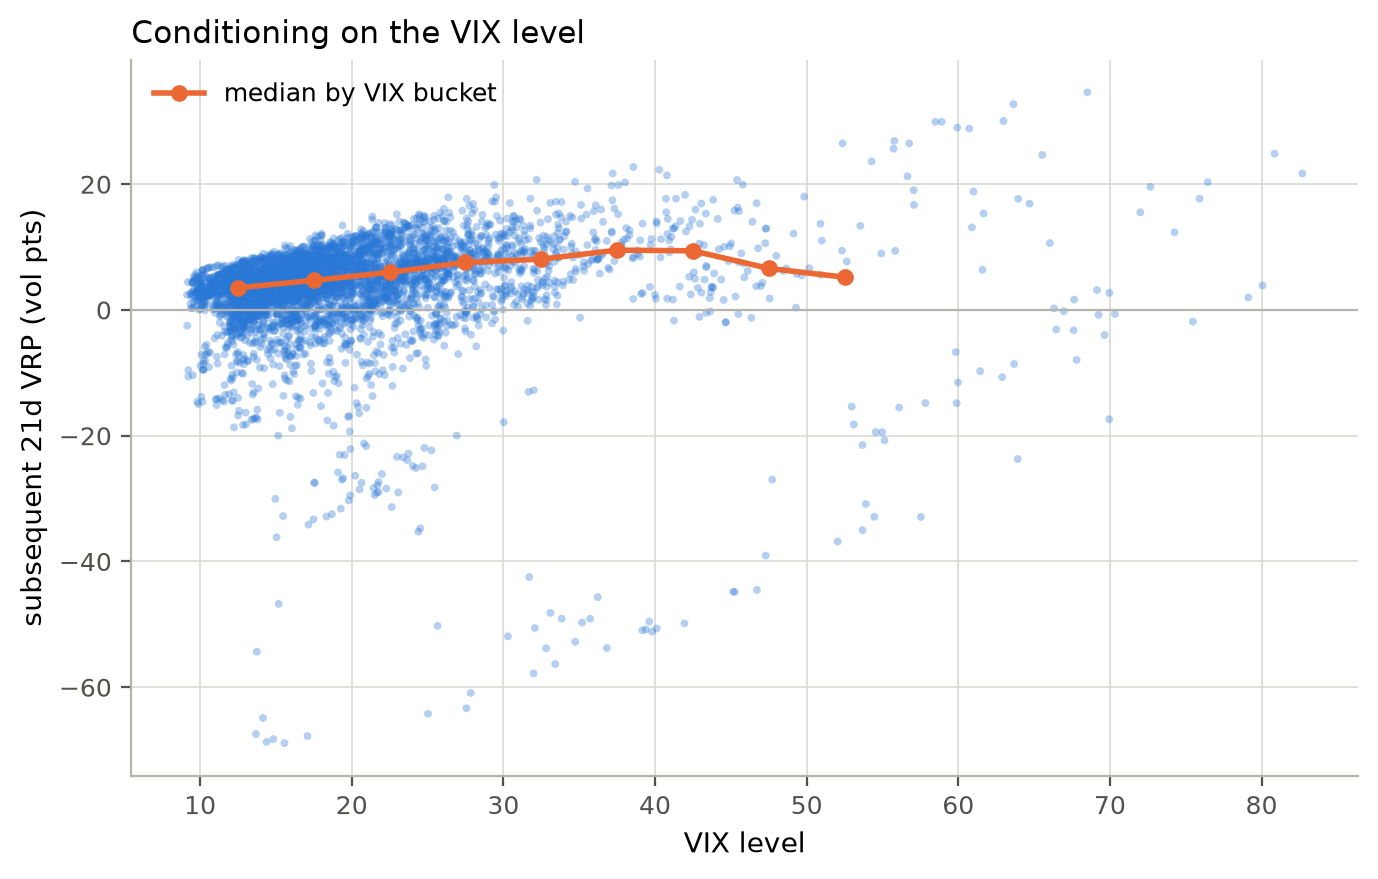

In [6]:
plot_vrp_vs_vix(df["vrp_expost_21d"], df["vix"]);

## Conditioning
The premium is *larger on average* when VIX is elevated — but the left tail grows faster than the mean. The extra carry is payment for spike risk, not free money.

In [7]:
conditional_table(df["vrp_expost_21d"], df["vix"],
                  bins=[0, 15, 20, 25, 35, 100],
                  labels=["<15", "15-20", "20-25", "25-35", ">35"]).round(2)

,mean,median,share_positive,p5,worst,n
bucket,,,,,,
<15,2.29,3.48,0.82,-6.38,-68.69,1761
15-20,3.49,4.71,0.84,-5.95,-68.89,1612
20-25,4.54,5.97,0.84,-8.49,-35.26,888
25-35,5.66,7.63,0.88,-3.30,-64.22,627
>35,4.74,8.88,0.79,-41.25,-53.76,253


## Both horizons + the tradeable proxy
The trailing proxy tracks the ex-post premium on average but lags at turning points — after a spike it *understates* the premium (trailing RV stays elevated while IV normalizes). The regime filter, not the proxy, must carry that risk.

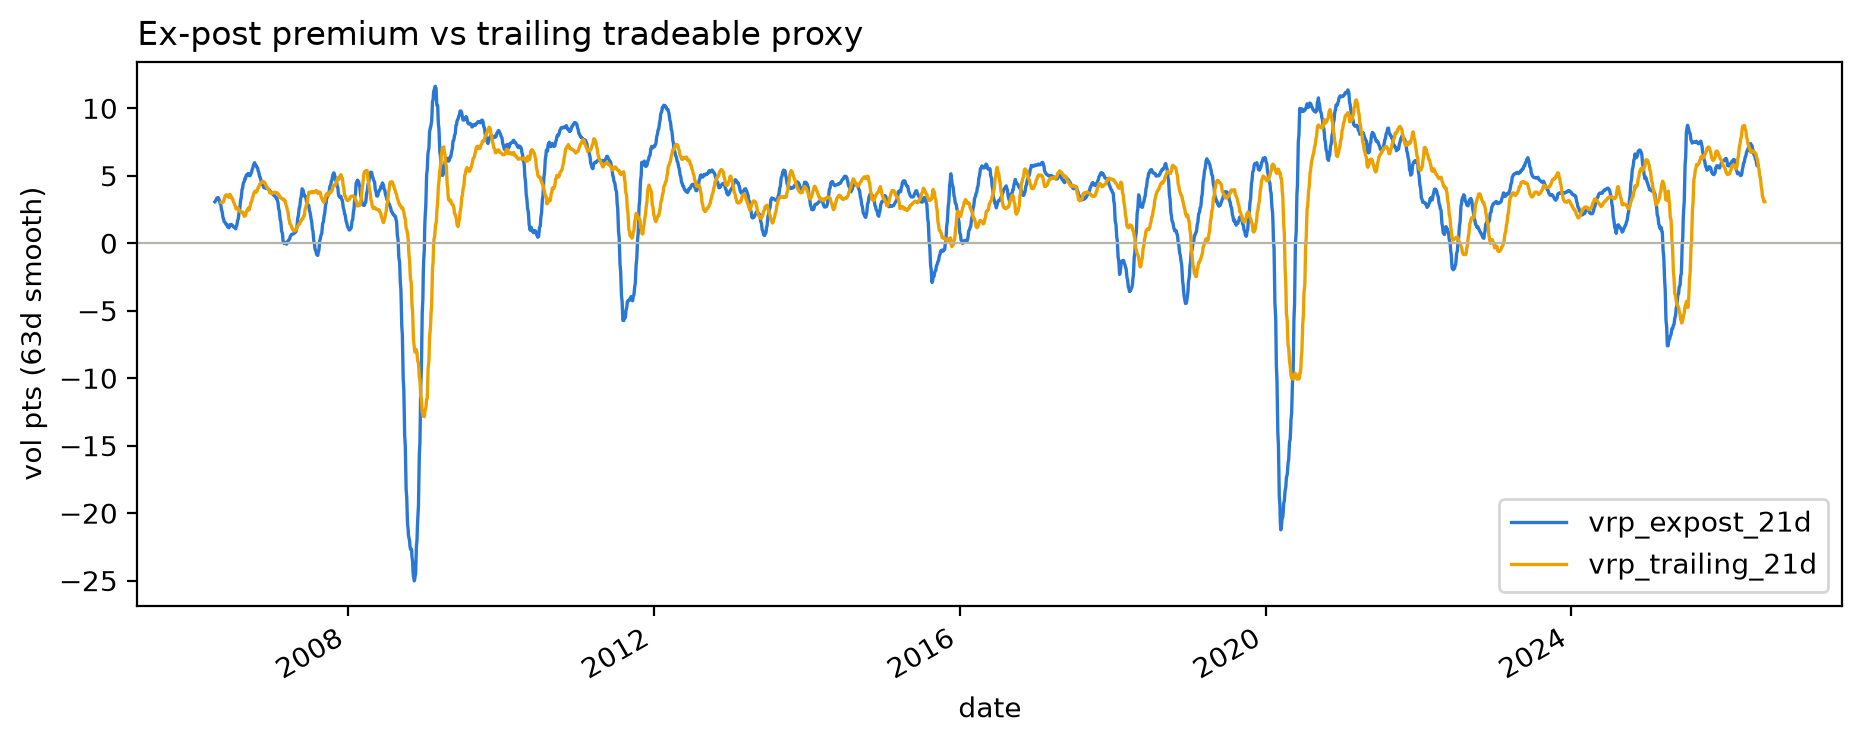

In [8]:
ax = (100*df[["vrp_expost_21d", "vrp_trailing_21d"]]).rolling(63).mean().plot(
    figsize=(11, 4), color=["#2a78d6", "#eda100"], lw=1.2)
ax.axhline(0, color="#b5b4ac", lw=0.8); ax.set_ylabel("vol pts (63d smooth)")
ax.set_title("Ex-post premium vs trailing tradeable proxy", loc="left");